In [1]:
import sys
from pathlib import Path

CODE_ROOT = Path("/Users/kamleshranabhat/Desktop/radiomics/full_pipeline")
for folder in ["", "scripts", "pre_processing", "feature_extraction", "post_processing"]:
    if str(CODE_ROOT / folder) not in sys.path:
        sys.path.insert(0, str(CODE_ROOT / folder))

import os
import numpy as np
import matplotlib.pyplot as plt

import SimpleITK as sitk

from scipy import ndimage
import pandas as pd
import math
from scripts import *
from roi_preparation import *


In [2]:
import yaml
config_path = Path("/Users/kamleshranabhat/Desktop/radiomics/full_pipeline/config_files/setup.yaml")

with open(config_path, "r") as f:
    config = yaml.safe_load(f)

config

{'DATA_ROOT': '/Users/kamleshranabhat/Desktop/radiomics/dataset',
 'IMAGES_DIR': '/Users/kamleshranabhat/Desktop/radiomics/dataset/imagesTr',
 'LABELS_DIR': '/Users/kamleshranabhat/Desktop/radiomics/dataset/labelTr',
 'PROJECT_ROOT': '/Users/kamleshranabhat/Desktop/radiomics/full_pipeline',
 'CODEBASE_DIR': '/Users/kamleshranabhat/Desktop/radiomics/full_pipeline',
 'OUTPUT_DIR': '/Users/kamleshranabhat/Desktop/radiomics/full_pipeline/outputs',
 'MASK_DIR': '/Users/kamleshranabhat/Desktop/radiomics/full_pipeline/outputs/masks',
 'FEATURE_DIR': '/Users/kamleshranabhat/Desktop/radiomics/full_pipeline/outputs/features',
 'TABLE_DIR': '/Users/kamleshranabhat/Desktop/radiomics/full_pipeline/outputs/tables',
 'FIGURE_DIR': '/Users/kamleshranabhat/Desktop/radiomics/full_pipeline/outputs/figures',
 'REGISTRATION_DIR': '/Users/kamleshranabhat/Desktop/radiomics/full_pipeline/outputs/registration',
 'BIAS_DIR': '/Users/kamleshranabhat/Desktop/radiomics/full_pipeline/outputs/bias_correction',
 'REP

In [3]:
label_image = load_image(label_path("BreastMRI023"))
test_index = (100.25, 200.5, 50.0)
print("ours     :", np.round(index_to_physical(test_index, label_image), 6))
print("SimpleITK:", np.round(label_image.TransformContinuousIndexToPhysicalPoint(test_index), 6))

ours     : [111.474974  50.113492  26.129539]
SimpleITK: [111.474974  50.113492  26.129539]


In [4]:
from timer import *

In [5]:
records = []
component_tables = {}
with Timer() as t:
    for case in list_case():
        case_records, components = prepare_rois(case)
        records += case_records
        component_tables[case] = components
manifest = pd.DataFrame(records)
manifest.to_csv(Path(config["TABLE_DIR"]) / "roi_manifest.csv", index=False)
print("stage 1 for %d patients in %.1f s" % (len(list_case()), t.seconds))
display(manifest.drop(columns=["mask_file", "spacing"]))

Time taken: 4.629889011383057 seconds
stage 1 for 5 patients in 4.6 s


,PatientID,Side,n_components_kept,n_voxels,volume_mm3,midline_x_mm,n_components_dropped_all_sides,voxels_dropped_all_sides
0,BreastMRI002,L,2,530410,236702.2,9.93,100,7506
1,BreastMRI002,R,1,530794,236873.6,9.93,100,7506
2,BreastMRI006,L,1,511147,238863.9,4.16,110,8577
3,BreastMRI006,R,2,678585,317109.3,4.16,110,8577
4,BreastMRI018,L,1,148049,66388.4,-4.48,173,12772
5,BreastMRI018,R,1,165028,74002.1,-4.48,173,12772
6,BreastMRI021,L,1,241624,133101.2,4.14,1604,20111
7,BreastMRI021,R,3,238260,131248.1,4.14,1604,20111
8,BreastMRI023,L,3,82489,65759.7,8.56,208,19874
9,BreastMRI023,R,2,150325,119838.2,8.56,208,19874


In [6]:
table = component_tables["BreastMRI021"]
print("BreastMRI023: %d components, %d kept" % (len(table), table["kept"].sum()))
display(table.head(8).round(2))

BreastMRI023: 1608 components, 4 kept


,component,n_voxels,centroid_x_mm,centroid_y_mm,centroid_z_mm,kept,side
0,1,241624,98.89,-37.73,-17.00,True,L
1,2,235212,-90.61,-40.41,-22.46,True,R
2,3,1830,-99.64,18.29,21.18,True,R
3,4,1218,-110.43,56.22,-18.87,True,R
4,5,840,-35.56,-36.40,-0.74,False,R
5,6,784,-114.53,20.80,27.41,False,R
6,7,666,-93.30,-19.35,54.03,False,R
7,8,517,122.46,-75.69,-42.60,False,L


In [7]:
balance = manifest.pivot(index="PatientID", columns="Side", values="volume_mm3") / 1000
balance.columns = ["left_cm3", "right_cm3"]
balance["left/right"] = balance["left_cm3"] / balance["right_cm3"]
display(balance.round({"left_cm3": 1, "right_cm3": 1, "left/right": 2}))

,left_cm3,right_cm3,left/right
PatientID,,,
BreastMRI002,236.7,236.9,1.00
BreastMRI006,238.9,317.1,0.75
BreastMRI018,66.4,74.0,0.90
BreastMRI021,133.1,131.2,1.01
BreastMRI023,65.8,119.8,0.55


In [8]:
from visualize import show_image_with_mask, overlay_mask

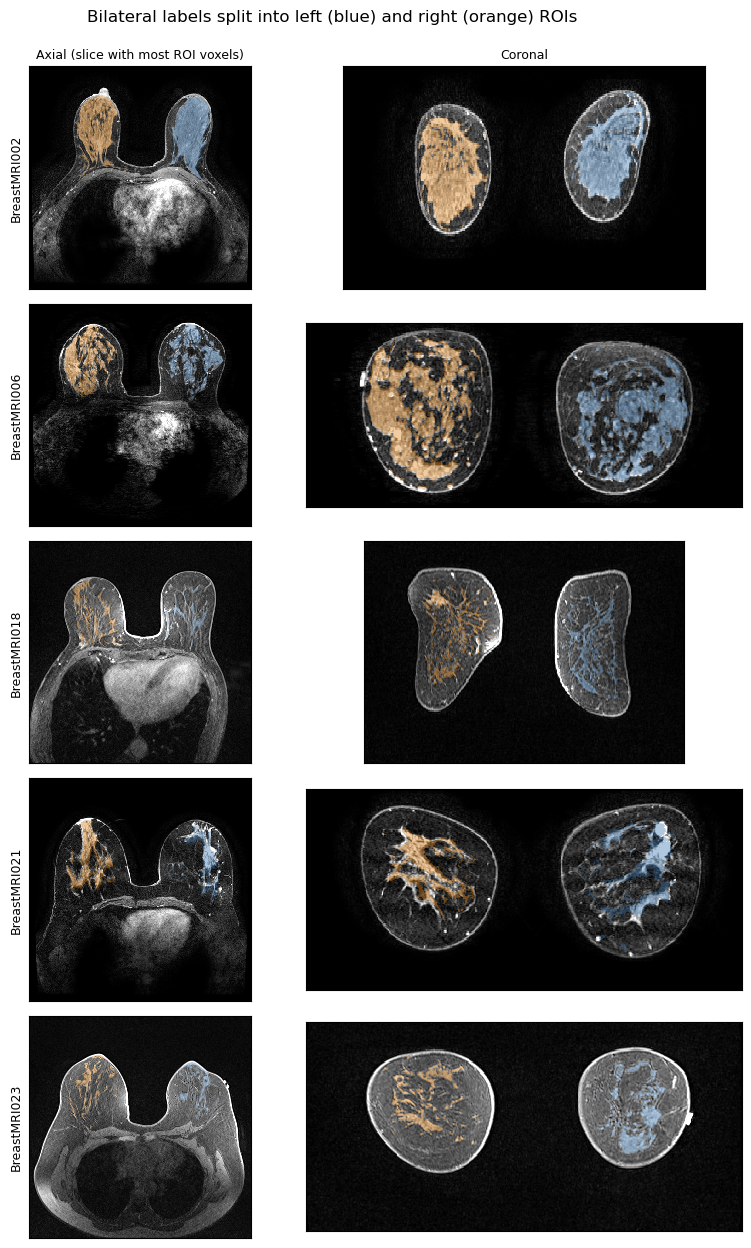

In [9]:
SIDE_COLOR = {"L": "#3a76af", "R": "#e08214"}
volumes = manifest.set_index(["PatientID", "Side"])["volume_mm3"]
cases = list_case()
fig, axes = plt.subplots(len(cases), 2, figsize=(8.5, 2.5 * len(cases)))
for row, case in enumerate(cases):
    reference_image = load_image(image_path(case, 0))
    image = array_from_image(reference_image).astype(float)
    sp = spacing_zyx(reference_image)
    masks = {side: array_from_image(load_image(mask_path(case, side))) > 0 for side in config["SIDES"]}
    both = masks["L"] | masks["R"]
    for col, axis in enumerate((0, 1)):
        ax = axes[row, col]
        index = largest_slice_index(both, axis)
        show_image_with_mask(ax, image, None, sp, axis=axis, index=index)
        for side in config["SIDES"]:
            overlay_mask(ax, masks[side], sp, axis=axis, index=index, color=SIDE_COLOR[side], contour=False)
            plane = radiological_view(masks[side], axis, index)
        if row == 0:
            ax.set_title(["Axial (slice with most ROI voxels)", "Coronal"][col], fontsize=9)
    axes[row, 0].set_ylabel(case, fontsize=9)

fig.suptitle("Bilateral labels split into left (blue) and right (orange) ROIs", y=0.995)
fig.tight_layout()
fig.savefig(Path(config["FIGURE_DIR"]) / "roi_qc_montage.png", dpi=120)
plt.show()